# Additional – K-Means Image Segmentation

**Mục tiêu:** áp dụng K-Means để phân đoạn ảnh bằng cách gom các pixel có màu RGB gần nhau vào cùng một cụm. Notebook này là phần mở rộng độc lập của project Lab03; notebook `Lab03.ipynb` về Customer Segmentation được giữ nguyên.

## Nội dung
1. Khởi tạo và kiểm tra dữ liệu ảnh
2. Tìm hiểu ảnh và tiền xử lý
3. Cài đặt K-Means (K-Means++)
4. Elbow Method với K = 1..8
5. Phân đoạn hai ảnh với nhiều giá trị K
6. So sánh và nhận xét kết quả

**Lưu ý:** K-Means ở đây phân cụm theo màu RGB, không sử dụng thông tin vị trí pixel. Vì vậy các vùng có màu tương tự có thể được gom chung dù nằm ở những vị trí khác nhau.

In [1]:
# 1. Import libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import time
import json
import sys

# 2. Locate project
def find_project_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "additional").exists():
            return p
    raise FileNotFoundError("Không tìm thấy data/additional.")

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

from src.additional import (
    load_rgb_image, image_to_pixels, KMeansFromScratch,
    make_sample, plot_elbow, plot_segmentation_comparison,
    plot_color_palette,
)

# 3. Define directories
IMAGE_DIR = PROJECT_ROOT / "data" / "additional"
REPORT_DIR = PROJECT_ROOT / "reports" / "additional_image_segmentation"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "additional_image_segmentation"
OUTPUT_DIR = FIGURE_DIR / "notebook_run"
PROGRESS_DIR = PROJECT_ROOT / "progress_results" / "image_segmentation"

for directory in [REPORT_DIR, FIGURE_DIR, OUTPUT_DIR, PROGRESS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# 4. Generate Markdown report
def write_segmentation_report(output_dir, elbow_df, palette_df, image_names, tested_k):
    lines = [
        "# Additional Image Segmentation Report",
        "",
        "## 1. Overview",
        f"- Input images: {len(image_names)}",
        f"- Tested K: {list(tested_k)}",
        "- Algorithm: K-Means++",
        "- Color space: RGB",
        "",
        "## 2. Elbow Results",
        elbow_df.to_markdown(index=False),
        "",
        "## 3. Color Palette Results",
        palette_df.to_markdown(index=False),
        "",
        "## 4. Segmentation Results",
    ]

    for image_name in image_names:
        stem = Path(image_name).stem
        lines.extend(["", f"### {image_name}"])

        for k in tested_k:
            filename = f"{stem}_segmented_k{k}.png"
            if (Path(output_dir) / filename).exists():
                lines.append(f"- K={k}: `{filename}`")

    report_path = REPORT_DIR / "notebook_image_segmentation_report.md"
    report_path.write_text("\n".join(lines), encoding="utf-8")
    return report_path

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)
print("Report function: ready")


Project root: c:\ML\Lab03_ML
Output directory: c:\ML\Lab03_ML\reports\figures\additional_image_segmentation\notebook_run
Report function: ready


## 2. Load images

Hai ảnh đầu vào được lấy từ `data/additional/`. Notebook tìm các tệp `image1.jpg` và `image2.jpg`; nếu tên tệp khác, hãy sửa danh sách `IMAGE_FILES` bên dưới.

image1.jpg: shape=(681, 1024, 3), dtype=uint8, min=0, max=255
image2.jpg: shape=(635, 900, 3), dtype=uint8, min=0, max=255


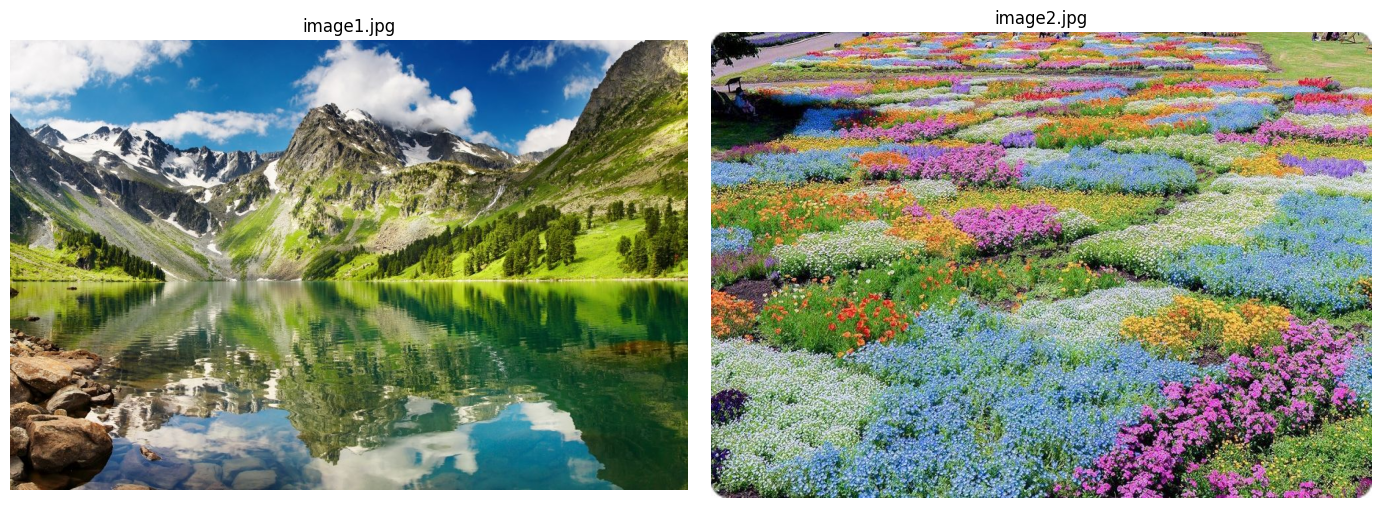

In [2]:
IMAGE_FILES = ["image1.jpg", "image2.jpg"]

images = {}
for filename in IMAGE_FILES:
    images[filename] = load_rgb_image(IMAGE_DIR / filename)

for name, arr in images.items():
    print(f"{name}: shape={arr.shape}, dtype={arr.dtype}, min={arr.min()}, max={arr.max()}")

fig, axes = plt.subplots(1, len(images), figsize=(14, 5))
if len(images) == 1:
    axes = [axes]
for ax, (name, arr) in zip(axes, images.items()):
    ax.imshow(arr); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()


## 3. Image preprocessing

Mỗi pixel được biểu diễn bằng vector `[R, G, B]`. Dữ liệu màu được chuyển về `float32` để tính khoảng cách Euclidean. Ảnh gốc được giữ nguyên; chỉ ma trận pixel dùng cho quá trình phân cụm được làm phẳng thành dạng `(số_pixel, 3)`.

In [3]:
pixel_data = {}
for name, arr in images.items():
    pixels, height, width = image_to_pixels(arr)
    pixel_data[name] = {"pixels": pixels, "height": height, "width": width}
    print(f"{name}: {len(pixels):,} pixels, {height} x {width}")


image1.jpg: 697,344 pixels, 681 x 1024
image2.jpg: 571,500 pixels, 635 x 900


## 4. K-Means implementation

Cài đặt dưới đây sử dụng:
- **K-Means++** để chọn tâm cụm ban đầu.
- Khoảng cách Euclidean trong không gian RGB.
- Cập nhật tâm bằng trung bình các pixel thuộc cụm.
- Dừng khi tâm cụm dịch chuyển nhỏ hơn `tol` hoặc đạt `max_iter`.

Để giảm thời gian chạy, bước tìm K dùng mẫu pixel ngẫu nhiên tối đa 20.000 điểm. Khi tạo ảnh phân đoạn, mô hình được fit trên tối đa 100.000 pixel rồi dự đoán nhãn cho toàn bộ pixel.

In [4]:
# KMeansFromScratch được import từ src/additional/kmeans.py
# Cài đặt gồm K-Means++ initialization, Euclidean distance và xử lý cụm rỗng.
print("Đã nạp KMeansFromScratch từ src.additional.kmeans")


Đã nạp KMeansFromScratch từ src.additional.kmeans


## 5. Elbow Method (K = 1..8)

Inertia là tổng bình phương khoảng cách từ mỗi pixel đến tâm cụm gần nhất. Inertia thường giảm khi K tăng; ta quan sát điểm mà tốc độ giảm bắt đầu chậm lại (elbow). Elbow chỉ là tiêu chí tham khảo, không tự động đảm bảo K tối ưu.

,image,K,inertia,iterations,seconds
0,image1.jpg,1,2.421213e+08,2,0.00
1,image1.jpg,2,1.093559e+08,9,0.02
2,image1.jpg,3,7.917404e+07,14,0.04
3,image1.jpg,4,4.780610e+07,22,0.06
4,image1.jpg,5,3.767266e+07,49,0.15
5,image1.jpg,6,3.230807e+07,34,0.16
6,image1.jpg,7,2.796965e+07,47,0.18
7,image1.jpg,8,2.377345e+07,43,0.17
8,image2.jpg,1,2.148383e+08,2,0.00
9,image2.jpg,2,1.006561e+08,14,0.03


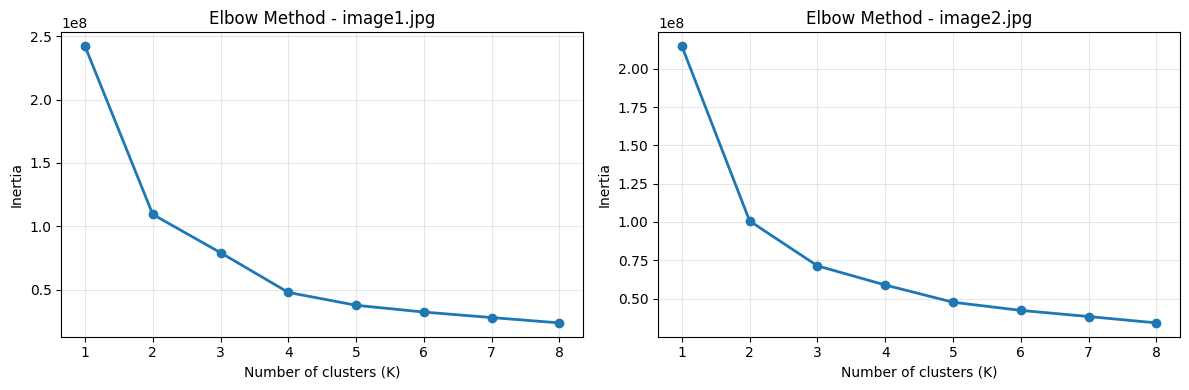

In [5]:
def make_sample(X, max_samples=20000, random_state=42):
    if len(X) <= max_samples:
        return X
    rng = np.random.default_rng(random_state)
    idx = rng.choice(len(X), size=max_samples, replace=False)
    return X[idx]

elbow_rows = []
for image_name, info in pixel_data.items():
    X_sample = make_sample(info["pixels"], max_samples=20000)
    for k in range(1, 9):
        start = time.time()
        model = KMeansFromScratch(n_clusters=k, max_iter=80, tol=1e-2, random_state=42)
        model.fit(X_sample)
        elbow_rows.append({
            "image": image_name,
            "K": k,
            "inertia": model.inertia_,
            "iterations": model.n_iter_,
            "seconds": time.time() - start
        })

elbow_df = pd.DataFrame(elbow_rows)
display(elbow_df.round(2))

plot_elbow(elbow_df)
plt.show()

## 6. Image segmentation

Thử nghiệm các mức K = 3, 5, 8 để quan sát ảnh hưởng của số cụm. Mỗi tâm cụm RGB đại diện cho một màu trong ảnh kết quả. Màu được gán lại cho từng pixel theo nhãn cụm gần nhất.

image1.jpg | K=3 | inertia(sample)=395,052,911 | iterations=14
image1.jpg | K=5 | inertia(sample)=188,130,466 | iterations=44
image1.jpg | K=8 | inertia(sample)=125,542,628 | iterations=100


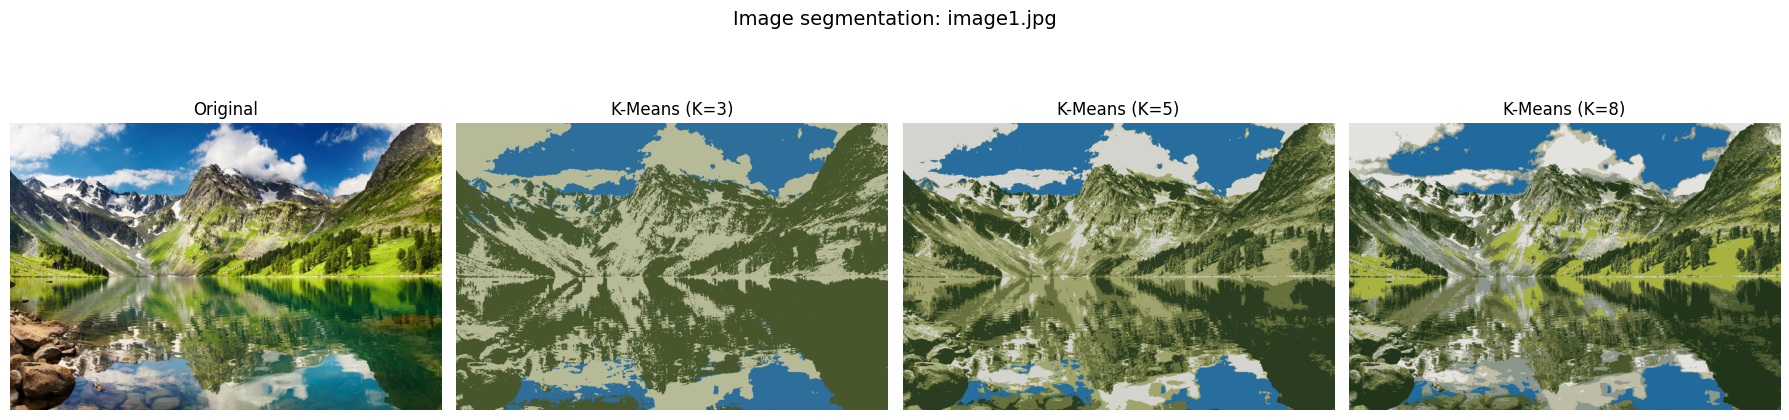

image2.jpg | K=3 | inertia(sample)=356,733,758 | iterations=28
image2.jpg | K=5 | inertia(sample)=239,748,182 | iterations=49
image2.jpg | K=8 | inertia(sample)=171,379,633 | iterations=73


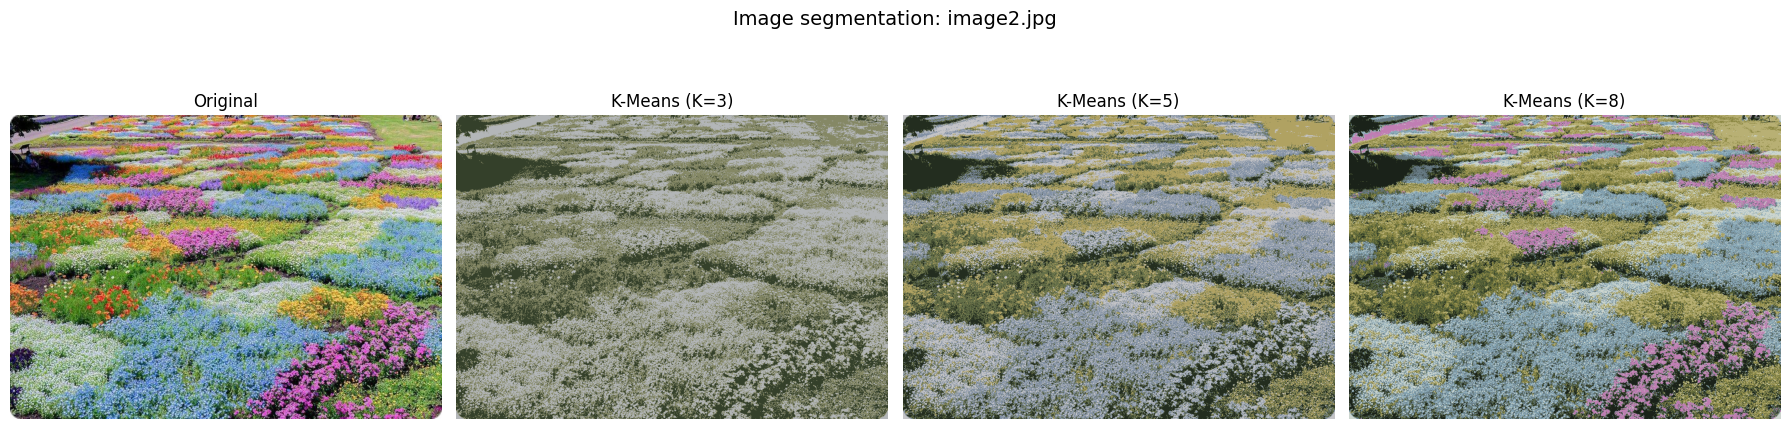

In [6]:
SEGMENTATION_K_VALUES = [3, 5, 8]
MAX_FIT_PIXELS = 100000

segmentation_results = {}

for image_name, info in pixel_data.items():
    X = info["pixels"]
    X_fit = make_sample(X, max_samples=MAX_FIT_PIXELS, random_state=42)

    for k in SEGMENTATION_K_VALUES:
        model = KMeansFromScratch(
            n_clusters=k, max_iter=100, tol=1e-2, random_state=42
        ).fit(X_fit)
        labels = model.predict(X)
        segmented = model.cluster_centers_[labels].clip(0, 255).astype(np.uint8)
        segmented = segmented.reshape(info["height"], info["width"], 3)

        segmentation_results[(image_name, k)] = {
            "model": model,
            "segmented": segmented,
            "labels": labels.reshape(info["height"], info["width"])
        }
        print(
            f"{image_name} | K={k} | inertia(sample)={model.inertia_:,.0f} "
            f"| iterations={model.n_iter_}"
        )

    # Display original and all selected K values
    fig, axes = plt.subplots(1, len(SEGMENTATION_K_VALUES) + 1, figsize=(18, 5))
    axes[0].imshow(images[image_name])
    axes[0].set_title("Original")
    axes[0].axis("off")
    for ax, k in zip(axes[1:], SEGMENTATION_K_VALUES):
        ax.imshow(segmentation_results[(image_name, k)]["segmented"])
        ax.set_title(f"K-Means (K={k})")
        ax.axis("off")
    fig.suptitle(f"Image segmentation: {image_name}", fontsize=14)
    plt.tight_layout()
    plt.show()

## 7. Color palette analysis

Bảng dưới đây hiển thị màu RGB của các tâm cụm. Tâm cụm có thể được hiểu là màu đại diện cho một nhóm pixel; tỷ lệ pixel của mỗi cụm cho biết mức độ phổ biến tương đối của màu đó.

,image,K,cluster,R,G,B,pixel_count,pixel_percent
0,image1.jpg,3,0,72,86,44,344583,49.41
1,image1.jpg,3,1,183,186,151,240157,34.44
2,image1.jpg,3,2,46,110,155,112604,16.15
3,image1.jpg,5,0,103,113,61,163812,23.49
4,image1.jpg,5,1,211,212,205,103282,14.81
5,image1.jpg,5,2,39,110,159,101552,14.56
6,image1.jpg,5,3,161,165,109,146044,20.94
7,image1.jpg,5,4,43,61,32,182654,26.19
8,image1.jpg,8,0,74,88,46,123519,17.71
9,image1.jpg,8,1,189,189,165,67875,9.73


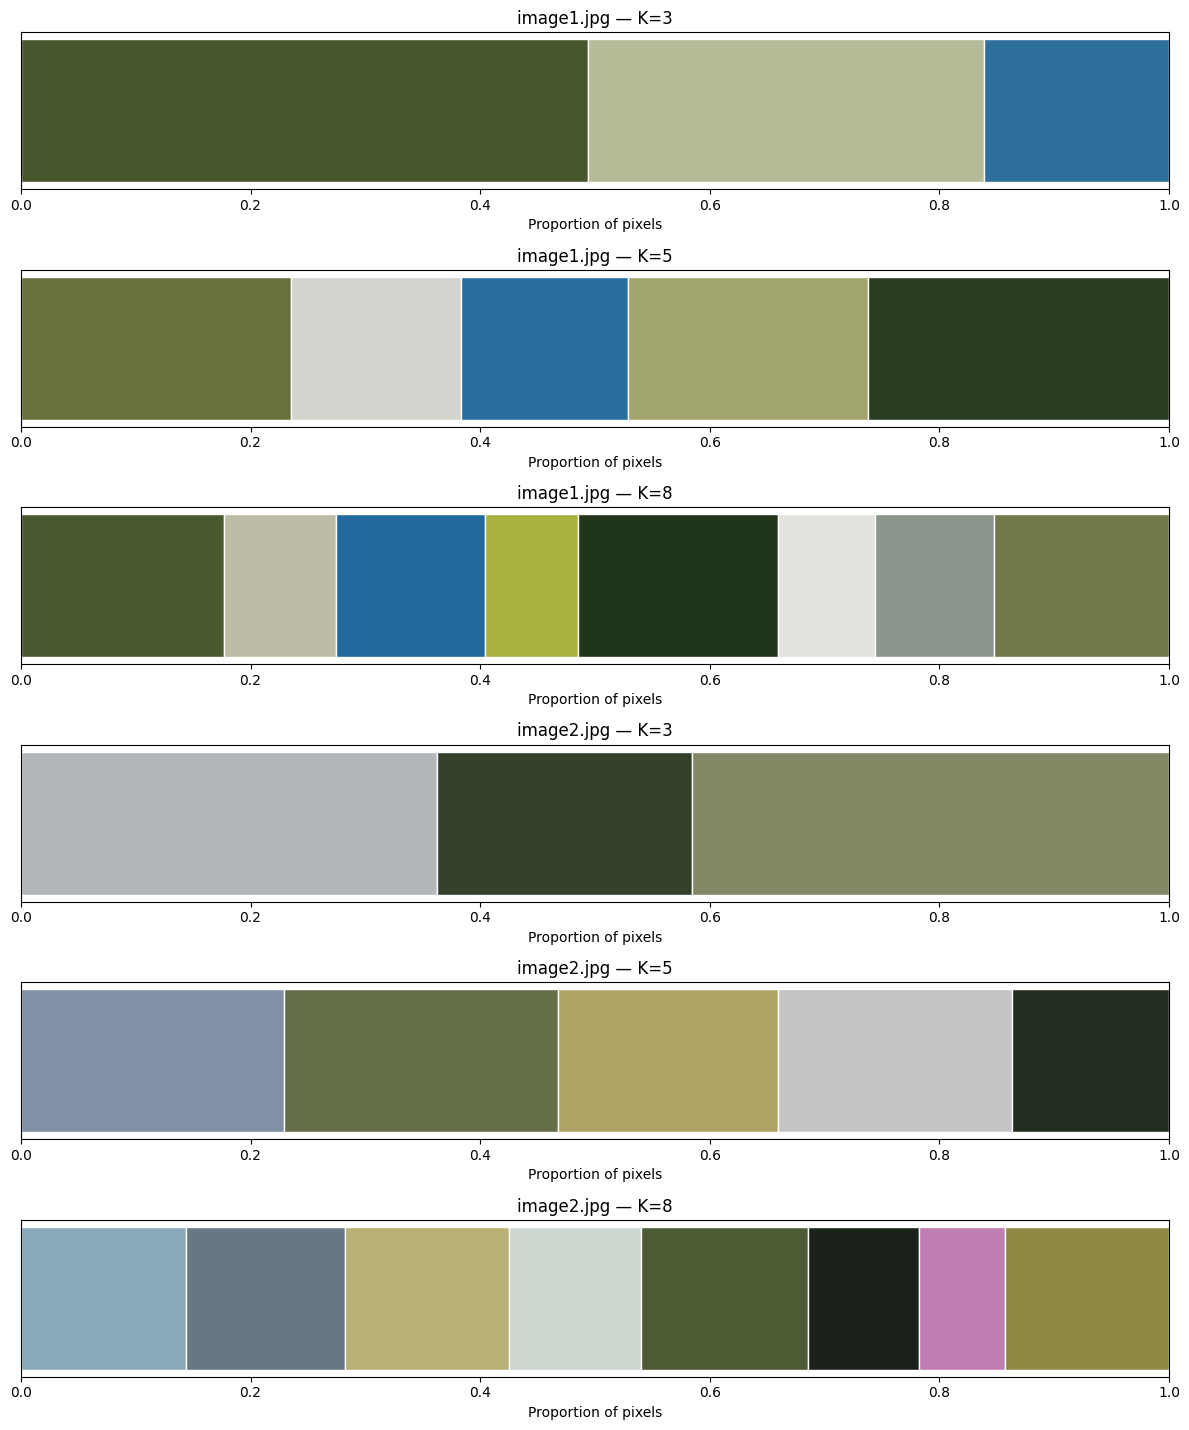

In [7]:
palette_rows = []
for (image_name, k), result in segmentation_results.items():
    labels = result["labels"].ravel()
    centers = result["model"].cluster_centers_
    counts = np.bincount(labels, minlength=k)
    for cluster_id, center in enumerate(centers):
        palette_rows.append({
            "image": image_name,
            "K": k,
            "cluster": cluster_id,
            "R": int(np.clip(center[0], 0, 255)),
            "G": int(np.clip(center[1], 0, 255)),
            "B": int(np.clip(center[2], 0, 255)),
            "pixel_count": int(counts[cluster_id]),
            "pixel_percent": 100 * counts[cluster_id] / len(labels)
        })

palette_df = pd.DataFrame(palette_rows)
display(palette_df.round(2))

fig, axes = plt.subplots(len(segmentation_results), 1, figsize=(12, 2.4 * len(segmentation_results)))
if len(segmentation_results) == 1:
    axes = [axes]
for ax, ((image_name, k), result) in zip(axes, segmentation_results.items()):
    centers = result["model"].cluster_centers_.clip(0, 255).astype(np.uint8)
    counts = np.bincount(result["labels"].ravel(), minlength=k)
    proportions = counts / counts.sum()
    # Draw a horizontal palette strip proportional to cluster sizes.
    start = 0.0
    for center, proportion in zip(centers, proportions):
        ax.barh([0], [proportion], left=start, color=center / 255, edgecolor="white")
        start += proportion
    ax.set_xlim(0, 1)
    ax.set_yticks([])
    ax.set_title(f"{image_name} — K={k}")
    ax.set_xlabel("Proportion of pixels")
plt.tight_layout()
plt.show()

## 8. Discussion

### 8.1. Phân tích kết quả

- **K nhỏ:** Số màu đại diện ít, ảnh được đơn giản hóa mạnh; một số chi tiết và chuyển sắc có thể bị mất.
- **K lớn:** Giữ được nhiều sắc thái màu hơn nhưng ảnh phân đoạn phức tạp hơn.
- **Elbow Method:** Chọn K tại vùng Inertia bắt đầu giảm chậm lại. Tuy nhiên, đường cong không phải lúc nào cũng có khuỷu rõ ràng.

### 8.2. Giới hạn của phương pháp

- K-Means chỉ dựa trên khoảng cách màu RGB, không nhận biết đối tượng hay ranh giới ngữ nghĩa.
- Các vùng không gian khác nhau nhưng có màu gần nhau có thể được gán vào cùng một cụm.
- Kết quả phụ thuộc vào kích thước ảnh, cách lấy mẫu pixel và tâm cụm khởi tạo.

### 8.3. Nhận xét từ thực nghiệm

Dựa trên hình ảnh kết quả, hãy nhận xét:

1. Ảnh biển: K nào phân biệt tốt hơn giữa bầu trời, mặt nước và bờ biển?
2. Ảnh Landmark 81: K nào giữ được cấu trúc tòa nhà và nền xung quanh rõ hơn?
3. Khi tăng K, những chi tiết nào được giữ lại và những vùng nào vẫn bị gộp chung?

## 9. Conclusion

K-Means có thể thực hiện phân đoạn ảnh bằng cách lượng tử hóa màu RGB thành K màu đại diện. Thí nghiệm trên hai ảnh cho thấy số cụm K ảnh hưởng trực tiếp đến mức độ đơn giản hóa và lượng chi tiết được giữ lại. Elbow Method hỗ trợ khảo sát K, nhưng lựa chọn cuối cùng cần kết hợp quan sát trực quan và mục tiêu phân đoạn. Đây là phân đoạn dựa trên màu, không phải nhận dạng vật thể.